# 이커머스 고객 분석 리포트: 누가 자주 오고 많이 사는가

쇼핑몰 주문 5,160건과 상품 200개 데이터를 `src/pipeline.py`의 `DataAnalyzer` 클래스로 처리하고, RFM 분석으로 단골 고객을 찾는다.

| 단계 | 내용 | 사용 메서드 |
|---|---|---|
| 1 | 데이터 로드와 기본 탐색 | `load_data()` |
| 2 | 결측치 처리 | `missing_report()`, `handle_missing_values()` |
| 3 | 멀티모달 피처 엔지니어링 (이미지, 텍스트) | `add_image_features()`, `add_image_advanced_features()`, `add_text_features()` |
| 4 | IQR 이상치 탐지와 처리 | `get_iqr_bounds()`, `detect_outliers()`, `handle_outliers()` |
| 5 | 통계 분석 (요약 통계, 상관계수) | `summary_statistics()`, `correlation()` |
| 6 | 범주형 빈도와 시계열 추세 | `monthly_sales()` |
| 7 | RFM 고객 세분화 | `calculate_rfm()`, `segment_customers()`, `segment_summary()` |
| 8 | 보너스: 코호트 재구매율 | `cohort_retention()` |
| 9 | 보너스: Plotly 인터랙티브 차트 | `px.scatter`, `px.line` |

- 데이터는 `data/generate_data.py`가 고정 시드(42)로 만든 합성 데이터다. 실행할 때마다 같은 결과가 나온다.
- 차트 6종: 히스토그램, 박스플롯, 막대그래프, 히트맵, 산점도, 라인차트
- 보너스 인터랙티브 차트 2종: `Plotly` 산점도, 라인차트 (9장)

In [1]:
import os  # 파일 경로를 다루는 기본 모듈
import sys  # 파이썬 import 경로를 다루는 기본 모듈
import time  # 실행 시간을 재는 기본 모듈

import numpy as np  # 배열 계산 라이브러리
import pandas as pd  # 표(DataFrame) 처리 라이브러리
import matplotlib.pyplot as plt  # 기본 그래프 라이브러리
import seaborn as sns  # 통계 차트를 쉽게 그리는 라이브러리

# 노트북 폴더의 상위 폴더(프로젝트 루트)를 import 경로에 추가한다
ROOT = os.path.abspath("..")  # 노트북 폴더의 한 단계 위 = 프로젝트 최상위 폴더
sys.path.insert(0, ROOT)  # 그 폴더에서 src를 찾을 수 있게 맨 앞에 추가한다
from src.constants import ORDERS_PATH, PRODUCTS_PATH, SEGMENT_ORDER  # 공통 상수: 파일 경로, 세그먼트 순서
from src.pipeline import DataAnalyzer  # 분석 클래스를 가져온다

FIG_DIR = os.path.join(ROOT, "docs", "figures")  # 차트 이미지를 저장할 폴더
os.makedirs(FIG_DIR, exist_ok=True)  # 폴더가 없으면 만든다

sns.set_theme(style="whitegrid")  # 차트에 흰 바탕과 격자선을 쓴다
pd.set_option("display.max_columns", None)  # 컬럼을 줄이지 않고 모두 보여준다
pd.set_option("display.float_format", "{:,.2f}".format)  # 소수는 천 단위 쉼표와 소수 2자리로 보여준다


def save(fig, name):  # 그림을 파일로 저장하는 도우미 함수
    # README에서 쓸 수 있도록 그림을 파일로도 저장한다
    fig.savefig(os.path.join(FIG_DIR, name), dpi=110, bbox_inches="tight")  # 해상도 110, 여백은 최소로 저장한다

## 1. 데이터 로드 및 기본 탐색

주문 데이터(`orders.csv`)와 상품 데이터(`products.csv`)를 `product_id`로 합쳐 하나의 표로 만든다.

In [2]:
analyzer = DataAnalyzer(  # 분석기를 만든다
    ORDERS_PATH,  # 주문 파일 경로
    product_path=PRODUCTS_PATH,  # 상품 파일 경로
)
df = analyzer.load_data(date_cols=["order_date", "registered_date"])  # 두 파일을 합쳐 읽고 날짜 컬럼을 날짜형으로 바꾼다
print(df.shape)  # (행 수, 열 수)를 출력한다
df.drop(columns="image_pixels").head()  # 긴 이미지 컬럼을 빼고 앞 5행을 보여준다

(5160, 13)


,order_id,customer_id,order_date,product_id,quantity,region,payment_method,product_name,category,price,rating,registered_date
0,100001,C00004,2024-01-01,P0175,1,Gwangju,Kakao Pay,Spicy Green Tea Mini,Food,"14,400.00",NaN,2025-02-09
1,100002,C00035,2024-01-01,P0100,2,Seoul,Kakao Pay,Portable Mouse,Electronics,"150,700.00",4.10,2024-07-11
2,100003,C00035,2024-01-01,P0101,1,Seoul,Naver Pay,Organic Olive Oil Mini,Food,"15,000.00",4.20,2025-07-02
3,100004,C00174,2024-01-01,P0181,3,Gyeonggi,Card,Illustrated Data Science,Books,"30,800.00",4.80,2024-02-22
4,100005,C00626,2024-01-01,P0178,1,Busan,Bank Transfer,Portable Keyboard Gift Set,Electronics,"214,100.00",5.00,2025-03-02


In [3]:
# image_pixels는 16x16x3 = 768개 숫자를 공백으로 이은 문자열이다
print(df["image_pixels"].iloc[0][:80], "...")  # 첫 번째 이미지 문자열의 앞 80글자를 보여준다
print("숫자 개수:", len(df["image_pixels"].iloc[0].split()))  # 공백으로 자른 조각 수 = 숫자 개수(768)

209 194 8 205 140 96 190 195 0 190 175 0 207 113 14 255 192 66 255 182 96 242 16 ...
숫자 개수: 768


In [4]:
df.info()  # 컬럼 이름, 비어 있지 않은 개수, 자료형을 보여준다

<class 'pandas.DataFrame'>
RangeIndex: 5160 entries, 0 to 5159
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         5160 non-null   int64         
 1   customer_id      5160 non-null   str           
 2   order_date       5160 non-null   datetime64[us]
 3   product_id       5160 non-null   str           
 4   quantity         5160 non-null   int64         
 5   region           5160 non-null   str           
 6   payment_method   5160 non-null   str           
 7   product_name     5160 non-null   str           
 8   category         5160 non-null   str           
 9   price            4791 non-null   float64       
 10  rating           4594 non-null   float64       
 11  registered_date  5160 non-null   datetime64[us]
 12  image_pixels     5160 non-null   str           
dtypes: datetime64[us](2), float64(2), int64(2), str(7)
memory usage: 524.2 KB


In [5]:
df.describe()  # 숫자 컬럼의 개수, 평균, 표준편차, 사분위수를 보여준다

,order_id,order_date,quantity,price,rating,registered_date
count,"5,160.00",5160,"5,160.00","4,791.00","4,594.00",5160
mean,"102,580.50",2025-02-14 11:38:13.953488,1.72,"72,043.04",4.07,2024-07-25 13:24:50.232558
min,"100,001.00",2024-01-01 00:00:00,1.00,"6,800.00",2.50,2023-06-02 00:00:00
25%,"101,290.75",2024-09-30 00:00:00,1.00,"21,500.00",3.80,2023-12-21 00:00:00
50%,"102,580.50",2025-02-05 00:00:00,1.00,"35,100.00",4.10,2024-07-24 00:00:00
75%,"103,870.25",2025-07-24 00:00:00,2.00,"77,400.00",4.30,2025-03-11 00:00:00
max,"105,160.00",2025-12-31 00:00:00,30.00,"469,200.00",5.00,2025-10-26 00:00:00
std,"1,489.71",NaN,2.82,"88,654.83",0.45,NaN


In [6]:
df.describe(include=["object"]).drop(columns="image_pixels")  # 글자 컬럼의 개수, 종류 수, 가장 흔한 값을 보여준다 (긴 이미지 컬럼은 뺀다)

/var/folders/4f/lc8c6_v12fj_wcg58t0frdzc0000gn/T/ipykernel_90933/222501903.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=["object"]).drop(columns="image_pixels")  # 글자 컬럼의 개수, 종류 수, 가장 흔한 값을 보여준다 (긴 이미지 컬럼은 뺀다)


,customer_id,product_id,region,payment_method,product_name,category
count,5160,5160,5160,5160,5160,5160
unique,1000,200,7,4,167,6
top,C00726,P0096,Seoul,Card,Cotton Jeans,Fashion
freq,28,62,1630,2618,93,1184


### 해석: 데이터 구조

| 데이터 유형 | 컬럼 |
|---|---|
| 수치형 | `price`, `quantity`, `rating` |
| 범주형 | `category`, `region`, `payment_method` |
| 날짜형 | `order_date`, `registered_date` |
| 텍스트 | `product_name` |
| 이미지(배열) | `image_pixels` (16x16 RGB, 768개 숫자) |
| 식별자 | `order_id`, `customer_id`, `product_id` |

- 크기: 5,160행 x 13열. 과제 조건(1,000건 이상, 8개 이상 컬럼, 3가지 이상 유형)을 만족한다.
- 기간: 2024-01-01 ~ 2025-12-31 (2년). 고객 1,000명, 상품 200개.
- 결측치: `info()`에서 `price`는 4,791개, `rating`은 4,594개만 값이 있다. 각각 369개(7.2%), 566개(11.0%)가 비어 있다.
- 치우침: `price` 평균 72,043원이 중앙값 35,100원의 2배가 넘는다. `quantity`도 평균 1.72인데 최대 30이다.
- 시사점: 평균은 소수의 고가 상품과 대량 주문에 끌려가므로, 대표값은 중앙값으로 보고 이상치 점검이 필요하다.
- RFM 준비: `customer_id`, `order_date`가 있고 `amount`는 `price x quantity`로 만든다. Recency 기준일은 마지막 거래일인 2025-12-31로 정한다.

## 2. 결측치 처리

`price`가 비어 있으면 주문 금액을 계산할 수 없고 RFM의 M(Monetary)이 틀어진다. 먼저 어디가 얼마나 비었는지 본다.

In [7]:
analyzer.missing_report()  # 컬럼별 빈 값 개수와 비율을 보여준다

,missing_count,missing_ratio
rating,566,10.97
price,369,7.15


In [8]:
# 카테고리별 결측 비율과 중앙값
pd.DataFrame({  # 카테고리별 요약표를 만든다
    "price_missing_%": df.groupby("category")["price"].apply(lambda s: s.isna().mean() * 100),  # 가격이 빈 비율(%)
    "price_median": df.groupby("category")["price"].median(),  # 가격 중앙값
    "rating_median": df.groupby("category")["rating"].median(),  # 평점 중앙값
}).sort_values("price_median", ascending=False)  # 가격 중앙값이 큰 카테고리부터 보여준다

,price_missing_%,price_median,rating_median
category,,,
Electronics,11.80,"184,400.00",4.00
Fashion,3.80,"44,200.00",4.30
Home,5.96,"39,100.00",4.00
Beauty,2.11,"27,900.00",4.10
Books,6.81,"16,900.00",4.10
Food,12.69,"15,600.00",4.10


### 대치 전략: 카테고리별 중앙값 (group_median)

- 카테고리마다 가격 수준이 크게 다르다. Electronics 중앙값은 184,400원, Food는 15,600원으로 약 12배 차이다.
- 전체 중앙값(35,100원)으로 채우면 전자기기는 싸게, 식품은 비싸게 채워진다. 그래서 `category`별 중앙값을 쓴다.
- 평균 대신 중앙값을 쓰는 이유: 가격 분포가 오른쪽으로 치우쳐 있어 평균이 극단값에 끌려간다.

In [9]:
price_before = df["price"].copy()  # 채우기 전 가격을 복사해 둔다
analyzer.handle_missing_values(strategy="group_median", group_col="category", columns=["price", "rating"])  # 카테고리별 중앙값으로 빈 값을 채운다
df = analyzer.df  # 채운 표를 다시 가져온다
print("남은 결측치:", int(df[["price", "rating"]].isna().sum().sum()))  # 남은 빈 값 수를 출력한다

filled = price_before.isna()  # 원래 비어 있던 행 표시
df.loc[filled].groupby("category")["price"].agg(["count", "first"]).rename(columns={"count": "filled_rows", "first": "filled_value"})  # 카테고리별로 채운 행 수와 채운 값을 보여준다

남은 결측치: 0


,filled_rows,filled_value
category,,
Beauty,20,"27,900.00"
Books,29,"16,900.00"
Electronics,137,"184,400.00"
Fashion,45,"44,200.00"
Food,98,"15,600.00"
Home,40,"39,100.00"


### 해석
- 결측치 935개(`price` 369 + `rating` 566)를 모두 채웠고 남은 결측치는 0개다.
- Food의 가격 결측 비율이 12.7%로 가장 높고 Beauty는 2.1%로 가장 낮다. 결측이 카테고리마다 고르지 않으므로 그룹별 대치가 더 안전하다.
- 시사점: 실제 서비스라면 Food, Electronics 상품 등록 화면에서 가격 입력을 필수로 바꾸면 결측을 줄일 수 있다.

## 3. 멀티모달 피처 엔지니어링

### 3-1. 이미지 배열을 숫자 피처로 바꾸기

CSV에 문자열로 저장된 픽셀을 `np.fromstring()`으로 되돌린다. 모든 행의 문자열을 하나로 이어 한 번에 읽은 뒤 `(행 수, 16, 16, 3)` 모양으로 `reshape`한다.

이미지 배열 모양: (5160, 16, 16, 3) uint8


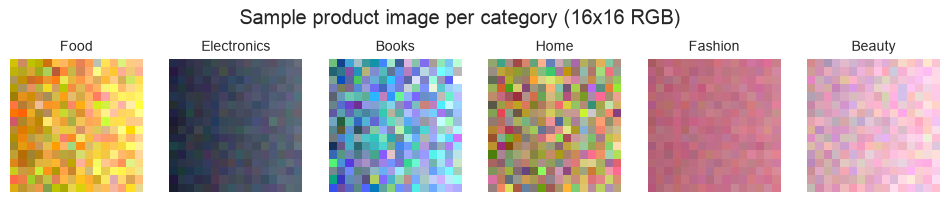

In [10]:
images = analyzer.parse_images("image_pixels", image_shape=(16, 16, 3))  # 픽셀 문자열을 이미지 배열로 바꾼다
print("이미지 배열 모양:", images.shape, images.dtype)  # 배열의 모양과 자료형을 출력한다

# 카테고리별 대표 이미지 1장씩 보기
sample = df.drop_duplicates("category")  # 카테고리마다 첫 행 하나씩만 남긴다
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))  # 가로로 6칸짜리 그림판을 만든다
for ax, (row_idx, cat) in zip(axes, sample["category"].items()):  # 칸과 카테고리를 짝지어 하나씩 돈다
    ax.imshow(images[row_idx])  # 그 행의 이미지를 그린다
    ax.set_title(cat, fontsize=10)  # 카테고리 이름을 제목으로 쓴다
    ax.axis("off")  # 눈금과 테두리를 숨긴다
fig.suptitle("Sample product image per category (16x16 RGB)")  # 그림 전체 제목
plt.show()  # 그림을 화면에 보여준다

### 반복문 대신 벡터 연산

- 이미지 배열은 `(N, 16, 16, 3)` 모양이다. 축 0은 이미지 번호, 축 1~3은 세로, 가로, 색이다.
- `images.mean(axis=(1, 2, 3))`은 "이미지 번호만 남기고 나머지 축을 모두 평균"이라는 뜻이다. 한 줄로 5,160개 이미지의 평균이 나온다.
- 아래는 for 반복문과 속도를 비교한 결과다. 결과는 같고 벡터 연산이 훨씬 빠르다.

In [11]:
imgs = images.astype(np.float64)  # 평균 계산을 위해 소수형으로 바꾼다

start = time.perf_counter()  # 시작 시각을 잰다
loop_mean = np.array([img.mean() for img in imgs])  # 비교용 반복문
loop_time = time.perf_counter() - start  # 반복문이 걸린 시간

start = time.perf_counter()  # 다시 시작 시각을 잰다
vec_mean = imgs.mean(axis=(1, 2, 3))  # 벡터 연산
vec_time = time.perf_counter() - start  # 벡터 연산이 걸린 시간

print("결과 동일:", np.allclose(loop_mean, vec_mean))  # 두 방법의 결과가 같은지 확인한다
print(f"반복문 {loop_time * 1000:.2f}ms, 벡터 연산 {vec_time * 1000:.2f}ms, 약 {loop_time / vec_time:.0f}배 빠름")  # 걸린 시간과 속도 차이를 출력한다

결과 동일: True
반복문 10.21ms, 벡터 연산 0.92ms, 약 11배 빠름


In [12]:
# 다운샘플링: arr[:, ::2, ::2] 로 16x16 -> 8x8
small = analyzer.parse_images("image_pixels", image_shape=(16, 16, 3), downsample_step=2)  # 2칸마다 1칸씩 뽑아 이미지를 줄인다
print("다운샘플링 후:", small.shape)  # 줄어든 모양을 출력한다

analyzer.add_image_features("image_pixels", image_shape=(16, 16, 3))  # 이미지 평균, 표준편차 컬럼을 추가한다
analyzer.add_image_advanced_features("image_pixels", image_shape=(16, 16, 3), n_brightness_bins=4)  # 보너스 1: 밝기 비율, 엣지 컬럼을 추가한다
df = analyzer.df  # 컬럼이 늘어난 표를 가져온다
df.groupby("category")[["image_brightness_mean", "image_brightness_std", "image_edge_strength", "image_brightness_bin_0_ratio", "image_brightness_bin_3_ratio"]].mean().sort_values("image_brightness_mean")  # 카테고리별 평균을 어두운 순으로 보여준다

다운샘플링 후: (5160, 8, 8, 3)


,image_brightness_mean,image_brightness_std,image_edge_strength,image_brightness_bin_0_ratio,image_brightness_bin_3_ratio
category,,,,,
Electronics,71.65,32.26,15.50,0.38,0.00
Home,138.89,38.45,14.13,0.00,0.01
Fashion,149.25,43.47,13.20,0.00,0.03
Food,160.78,70.08,14.50,0.00,0.08
Books,172.14,43.62,15.68,0.00,0.20
Beauty,205.02,33.58,14.44,0.00,0.73


### 해석: 이미지 피처
- `image_brightness_mean`(밝기 평균): Electronics가 71.7로 가장 어둡고 Beauty가 205.0으로 가장 밝다. 이미지 숫자만으로도 카테고리가 구분된다.
- `image_brightness_std`(밝기 퍼짐): Food가 70.1로 가장 크다. 색과 무늬가 복잡한 사진이라는 뜻이다.
- 보너스 피처: `image_brightness_bin_0~3_ratio`은 밝기를 4구간으로 나눈 픽셀 비율이고, `image_edge_strength`는 이웃 픽셀 간 밝기 차이의 평균(윤곽 강도)이다.
- 시사점: 이미지 밝기는 이후 상품 분류 모델에서 카테고리를 맞히는 입력 피처로 쓸 수 있다.

### 3-2. 텍스트 피처

In [13]:
analyzer.add_text_features("product_name")  # 상품명 단어 수, 글자 수 컬럼을 추가한다
df = analyzer.df  # 컬럼이 늘어난 표를 가져온다
df[["product_name", "name_word_count", "name_length"]].drop_duplicates().head()  # 상품명과 새 컬럼을 중복 없이 앞 5행 보여준다

,product_name,name_word_count,name_length
0,Spicy Green Tea Mini,4,20
1,Portable Mouse,2,14
2,Organic Olive Oil Mini,4,22
3,Illustrated Data Science,3,24
4,Portable Keyboard Gift Set,4,26


In [14]:
df[["name_word_count", "name_length"]].describe()  # 단어 수와 글자 수의 통계를 보여준다

,name_word_count,name_length
count,"5,160.00","5,160.00"
mean,3.00,17.93
std,0.87,4.68
min,2.00,8.00
25%,2.00,14.00
50%,3.00,18.00
75%,4.00,21.00
max,5.00,30.00


### 해석: 텍스트 피처
- 상품명은 평균 3.0단어, 17.9글자이고 가장 긴 이름은 30글자다.
- `name_length`와 `amount`의 상관계수는 0.00이다(5장). 이름 길이는 구매 금액과 관계가 없다.
- 시사점: 상품명 길이를 늘리는 식의 단순한 변경은 매출에 영향이 작을 가능성이 높다. 이름 안의 키워드(예: Gift Set, Pro)를 따로 보는 분석이 더 의미 있다.

## 4. 이상치 탐지 (IQR)

주문 금액 `amount = price x quantity`를 만들고 IQR 방식으로 이상치를 찾는다.

- Q1(25%)과 Q3(75%) 사이 거리를 IQR이라고 한다.
- `Q1 - 1.5 x IQR`보다 작거나 `Q3 + 1.5 x IQR`보다 크면 이상치로 본다.
- `threshold`(1.5)는 메서드 인자로 바꿀 수 있다.

In [15]:
analyzer.add_amount("price", "quantity")  # 주문 금액 = 가격 x 수량 컬럼을 추가한다
df = analyzer.df  # 컬럼이 늘어난 표를 가져온다

for t in [1.5, 3.0]:  # 임계값 두 가지를 비교한다
    lower, upper = analyzer.get_iqr_bounds("amount", threshold=t)  # 정상 범위를 구한다
    out = analyzer.detect_outliers("amount", threshold=t)  # 범위 밖 이상치 행을 찾는다
    print(f"threshold={t}: 정상 범위 {lower:,.0f} ~ {upper:,.0f}원, 이상치 {len(out)}건 ({len(out) / len(df) * 100:.1f}%)")  # 범위와 이상치 수를 출력한다

outliers = analyzer.detect_outliers("amount", threshold=1.5)  # 기본 임계값 1.5의 이상치 행
outliers["category"].value_counts()  # 이상치가 어느 카테고리에 몰려 있는지 센다

threshold=1.5: 정상 범위 -119,238 ~ 270,262원, 이상치 550건 (10.7%)
threshold=3.0: 정상 범위 -265,300 ~ 416,325원, 이상치 244건 (4.7%)


category
Electronics    473
Fashion         20
Beauty          19
Books           15
Home            12
Food            11
Name: count, dtype: int64

### 처리 방법 결정
- threshold 1.5에서 550건(10.7%)이 이상치다. 그중 473건(86%)이 Electronics다. 비싼 전자기기 주문이라 잘못된 값이 아니다.
- 그래서 행을 지우지 않는다. 지우면 실제 매출이 사라져 RFM의 M이 틀어진다.
- 대신 `handle_outliers(method="clip")`으로 상한값(270,262.5원)에 맞춘 `amount_clipped`를 따로 만들어 분포 분석과 시각화에만 쓴다. RFM은 원본 `amount`를 쓴다.

In [16]:
amount_raw = df["amount"].copy()  # 처리 전 주문 금액을 복사해 둔다
analyzer.df["amount_clipped"] = amount_raw  # 자를 용도의 새 컬럼에 같은 값을 넣는다
analyzer.handle_outliers("amount_clipped", threshold=1.5, method="clip")  # 새 컬럼만 경계값으로 자른다 (원본 amount는 그대로)
df = analyzer.df  # 바뀐 표를 가져온다

compare = pd.DataFrame({"before": amount_raw.describe(), "after": df["amount_clipped"].describe()})  # 처리 전후 통계를 나란히 놓는다
compare.loc["skew"] = [amount_raw.skew(), df["amount_clipped"].skew()]  # 왜도(치우친 정도) 행을 추가한다
compare  # 비교표를 보여준다

,before,after
count,"5,160.00","5,160.00"
mean,"118,253.66","85,839.90"
std,"299,433.36","83,089.75"
min,"6,800.00","6,800.00"
25%,"26,825.00","26,825.00"
50%,"48,600.00","48,600.00"
75%,"124,200.00","124,200.00"
max,"11,494,600.00","270,262.50"
skew,18.82,1.22


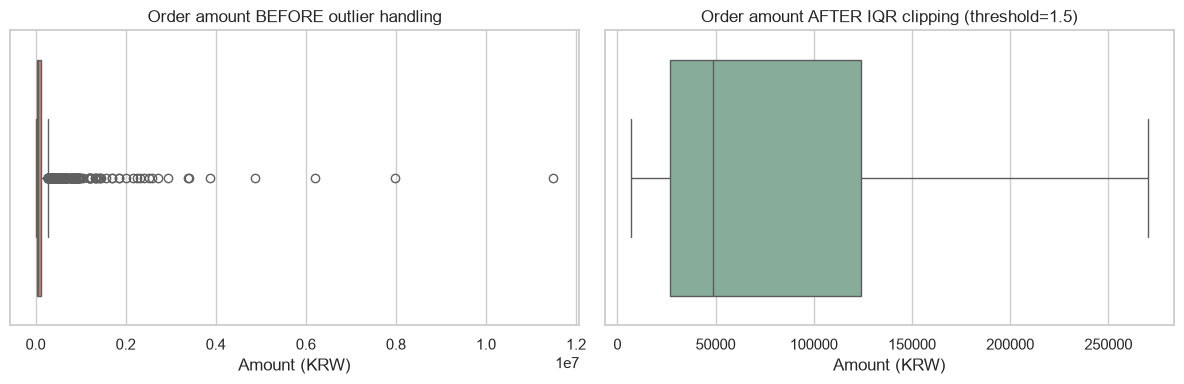

In [17]:
# 차트 2: 박스플롯 - 이상치 처리 전후 비교
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # 좌우 2칸 그림판
sns.boxplot(x=amount_raw, ax=axes[0], color="#e07a5f")  # 왼쪽: 처리 전 박스플롯
axes[0].set_title("Order amount BEFORE outlier handling")  # 왼쪽 제목
axes[0].set_xlabel("Amount (KRW)")  # 왼쪽 가로축 이름
sns.boxplot(x=df["amount_clipped"], ax=axes[1], color="#81b29a")  # 오른쪽: 처리 후 박스플롯
axes[1].set_title("Order amount AFTER IQR clipping (threshold=1.5)")  # 오른쪽 제목
axes[1].set_xlabel("Amount (KRW)")  # 오른쪽 가로축 이름
plt.tight_layout()  # 칸 사이 여백을 자동으로 맞춘다
save(fig, "boxplot_outlier.png")  # 이미지 파일로 저장한다
plt.show()  # 화면에 보여준다

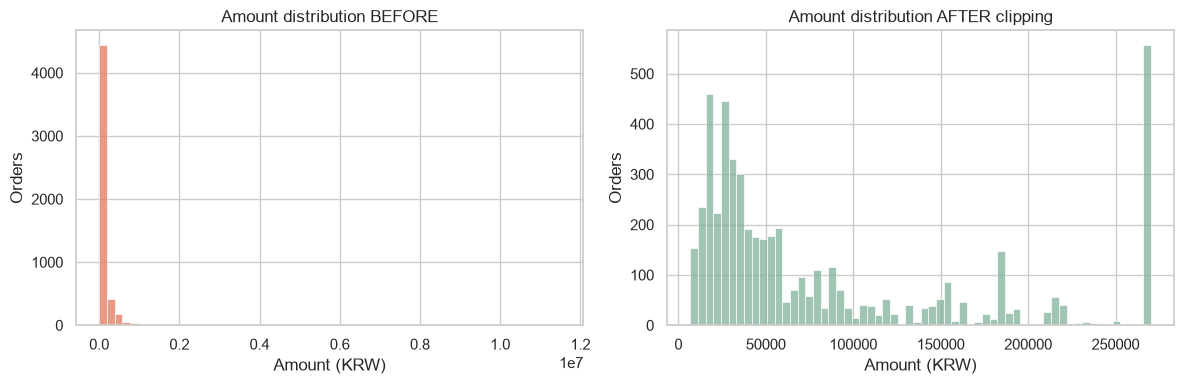

In [18]:
# 차트 1: 히스토그램 - 처리 전후 분포 변화
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # 좌우 2칸 그림판
sns.histplot(x=amount_raw, bins=60, ax=axes[0], color="#e07a5f")  # 왼쪽: 처리 전 분포
axes[0].set_title("Amount distribution BEFORE")  # 왼쪽 제목
axes[0].set_xlabel("Amount (KRW)")  # 왼쪽 가로축 이름
axes[0].set_ylabel("Orders")  # 왼쪽 세로축 이름
sns.histplot(x=df["amount_clipped"], bins=60, ax=axes[1], color="#81b29a")  # 오른쪽: 처리 후 분포
axes[1].set_title("Amount distribution AFTER clipping")  # 오른쪽 제목
axes[1].set_xlabel("Amount (KRW)")  # 오른쪽 가로축 이름
axes[1].set_ylabel("Orders")  # 오른쪽 세로축 이름
plt.tight_layout()  # 칸 사이 여백을 자동으로 맞춘다
plt.show()  # 화면에 보여준다

### 해석: 이상치 처리 전후
- 처리 전 최대값은 11,494,600원, 처리 후는 270,262.5원이다. 왜도(skew)는 18.8에서 1.2로 줄었다.
- 표준편차는 299,433원에서 83,090원으로 줄었지만 중앙값은 48,600원 그대로다. clip은 가운데 데이터를 건드리지 않는다.
- 시사점: 평균 객단가(118,254원)는 일부 대량, 고가 주문 때문에 부풀려져 있다. 마케팅 목표는 중앙값 기준으로 잡는 것이 현실적이다.

## 5. 통계 분석

### 5-1. 요약 통계

In [19]:
stat_cols = ["price", "quantity", "amount", "amount_clipped", "rating", "image_brightness_mean", "image_brightness_std"]  # 통계를 낼 컬럼 목록
analyzer.summary_statistics(stat_cols)  # 평균, 중앙값, 표준편차, 사분위수, IQR 표를 보여준다

,mean,median,std,min,q1,q3,max,iqr
price,"72,974.98","35,500.00","87,933.06","6,800.00","21,500.00","81,400.00","469,200.00","59,900.00"
quantity,1.72,1.00,2.82,1.00,1.00,2.00,30.00,1.00
amount,"118,253.66","48,600.00","299,433.36","6,800.00","26,825.00","124,200.00","11,494,600.00","97,375.00"
amount_clipped,"85,839.90","48,600.00","83,089.75","6,800.00","26,825.00","124,200.00","270,262.50","97,375.00"
rating,4.08,4.10,0.43,2.50,3.90,4.30,5.00,0.40
image_brightness_mean,144.28,152.59,45.19,55.27,130.27,170.13,220.50,39.85
image_brightness_std,42.48,38.62,13.57,17.86,33.94,47.73,75.31,13.79


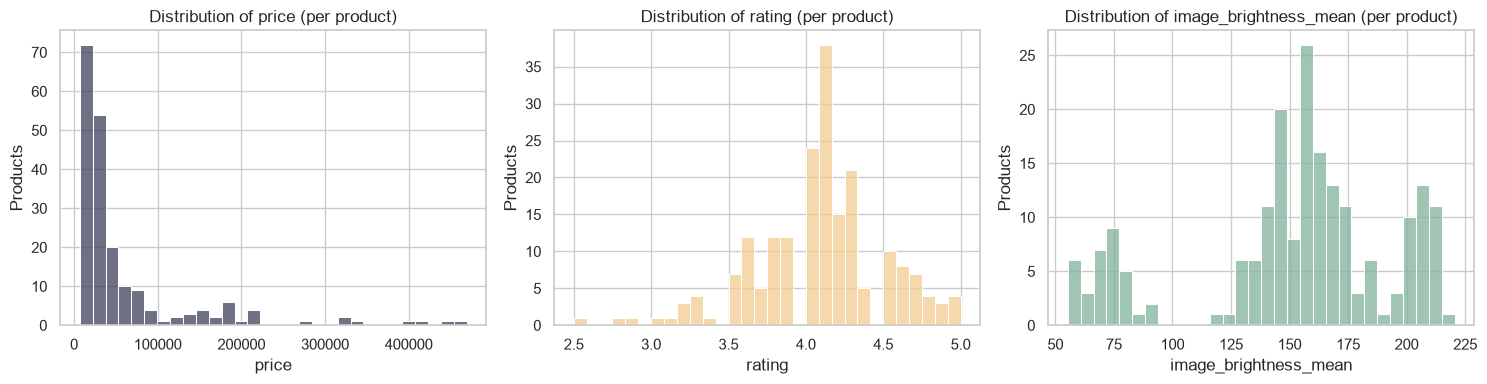

In [20]:
# 차트 1-2: 히스토그램 - 주요 수치형 변수 분포
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # 가로 3칸 그림판
for ax, col, color in zip(axes, ["price", "rating", "image_brightness_mean"], ["#3d405b", "#f2cc8f", "#81b29a"]):  # 칸, 컬럼, 색을 짝지어 돈다
    sns.histplot(x=df.drop_duplicates("product_id")[col], bins=30, ax=ax, color=color)  # 상품 단위(중복 제거)로 분포를 그린다
    ax.set_title(f"Distribution of {col} (per product)")  # 제목
    ax.set_xlabel(col)  # 가로축 이름
    ax.set_ylabel("Products")  # 세로축 이름
plt.tight_layout()  # 칸 사이 여백을 자동으로 맞춘다
save(fig, "histogram.png")  # 이미지 파일로 저장한다
plt.show()  # 화면에 보여준다

### 해석: 요약 통계
- `price`: 평균 72,975원, 중앙값 35,500원, 표준편차 87,933원. 평균이 중앙값의 2배이고 오른쪽 꼬리가 길다.
- `quantity`: 중앙값 1, Q3 2. 대부분 1~2개를 사고 IQR이 1에 불과하다.
- `rating`: 평균 4.08, IQR 0.40(3.90~4.30). 평점이 좁은 구간에 몰려 있어 상품 간 차별성이 작다.
- 시사점: 평점은 변별력이 낮으므로 추천 순위를 정할 때 평점보다 구매 빈도나 재구매율을 함께 써야 한다.

### 5-2. 상관 분석

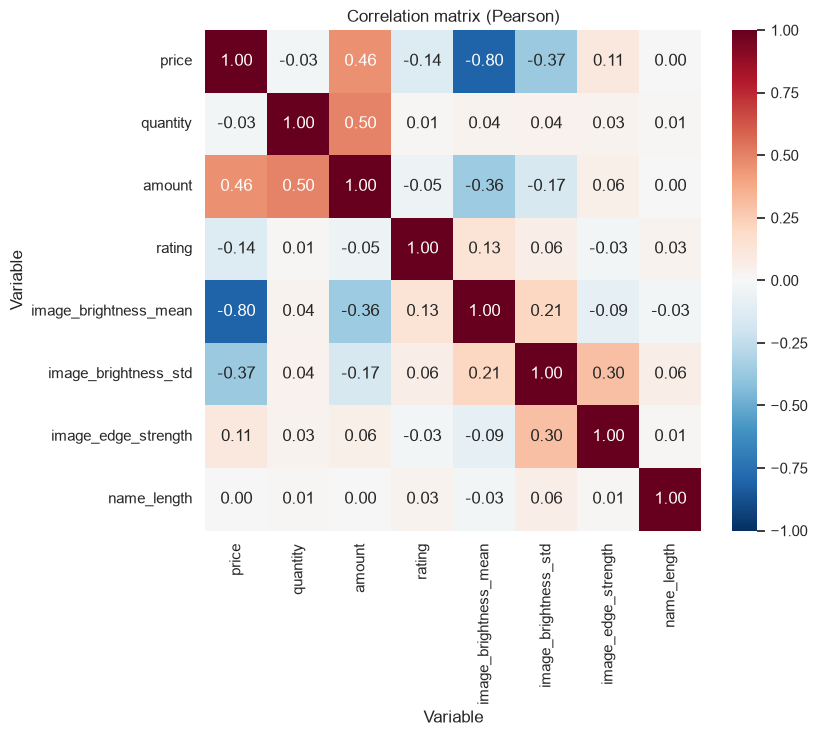

In [21]:
corr_cols = ["price", "quantity", "amount", "rating", "image_brightness_mean", "image_brightness_std", "image_edge_strength", "name_length"]  # 상관을 볼 컬럼 목록
corr = analyzer.correlation(corr_cols)  # 상관계수 표를 만든다

# 차트 4: 히트맵 - 상관행렬
fig, ax = plt.subplots(figsize=(8, 6.5))  # 그림판 한 칸
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)  # 칸마다 숫자를 적고 -1~1을 파랑~빨강으로 칠한다
ax.set_title("Correlation matrix (Pearson)")  # 제목
ax.set_xlabel("Variable")  # 가로축 이름
ax.set_ylabel("Variable")  # 세로축 이름
save(fig, "heatmap_corr.png")  # 이미지 파일로 저장한다
plt.show()  # 화면에 보여준다

In [22]:
pairs = [("price", "amount"), ("quantity", "amount"), ("price", "image_brightness_mean"), ("price", "rating"), ("name_length", "amount")]  # 해석할 변수 쌍 5개
pd.DataFrame([(a, b, corr.loc[a, b]) for a, b in pairs], columns=["var_1", "var_2", "pearson_r"])  # 쌍마다 상관계수를 뽑아 표로 만든다

,var_1,var_2,pearson_r
0,price,amount,0.46
1,quantity,amount,0.50
2,price,image_brightness_mean,-0.80
3,price,rating,-0.14
4,name_length,amount,0.00


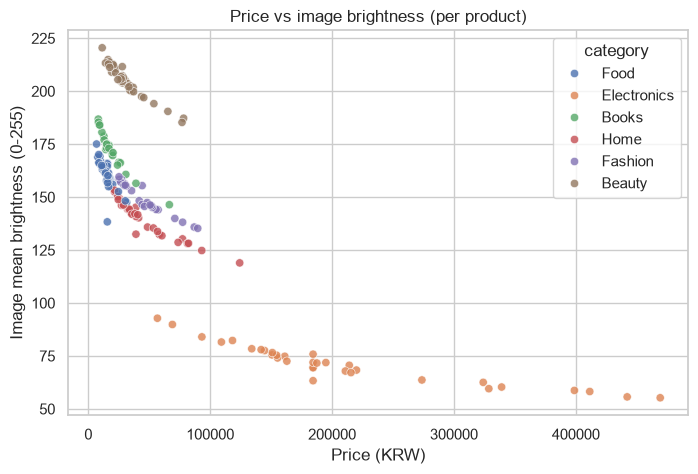

category
Beauty        -0.96
Books         -0.89
Electronics   -0.92
Fashion       -0.96
Food          -0.76
Home          -0.94
Name: within_category_r, dtype: float64

In [23]:
# 차트 5: 산점도 - 가격과 이미지 밝기 (상품 단위)
products = df.drop_duplicates("product_id")  # 상품마다 한 행만 남긴다
fig, ax = plt.subplots(figsize=(8, 5))  # 그림판 한 칸
sns.scatterplot(data=products, x="price", y="image_brightness_mean", hue="category", alpha=0.8, ax=ax)  # 가격(가로)과 밝기(세로)를 점으로 찍고 카테고리별로 색을 나눈다
ax.set_title("Price vs image brightness (per product)")  # 제목
ax.set_xlabel("Price (KRW)")  # 가로축 이름
ax.set_ylabel("Image mean brightness (0-255)")  # 세로축 이름
save(fig, "scatter_price_img.png")  # 이미지 파일로 저장한다
plt.show()  # 화면에 보여준다

# 카테고리 안에서도 관계가 유지되는지 확인 (카테고리가 만든 착시인지 점검)
products.groupby("category").apply(lambda g: g["price"].corr(g["image_brightness_mean"])).rename("within_category_r")  # 카테고리 안에서만 가격과 밝기의 상관계수를 구한다

### 해석: 상관계수

| 변수 쌍 | r | 해석 |
|---|---|---|
| price - amount | 0.46 | 비싼 상품일수록 주문 금액이 크다. 중간 정도 양의 관계 |
| quantity - amount | 0.50 | 수량도 금액에 비슷한 크기로 영향을 준다. 대량 주문이 금액 이상치를 만든다 |
| price - image_brightness_mean | -0.80 | 비싼 상품일수록 이미지가 어둡다. 강한 음의 관계 |
| price - rating | -0.14 | 거의 관계없다. 비싸다고 평점이 높지 않다 |
| name_length - amount | 0.00 | 관계없다 |

- `price`와 `image_brightness_mean`의 -0.80은 "Electronics가 비싸고 어둡다"는 카테고리 효과일 수 있다. 그래서 카테고리 안에서 다시 계산했고, 6개 카테고리 모두 -0.76 ~ -0.96으로 관계가 유지됐다.
- 시사점: 이미지 밝기는 가격대를 추정하는 보조 피처가 될 수 있다. 단, 상관은 인과가 아니므로 "어둡게 찍으면 비싸게 팔린다"는 결론은 낼 수 없다.

## 6. 범주형 빈도와 시계열 추세

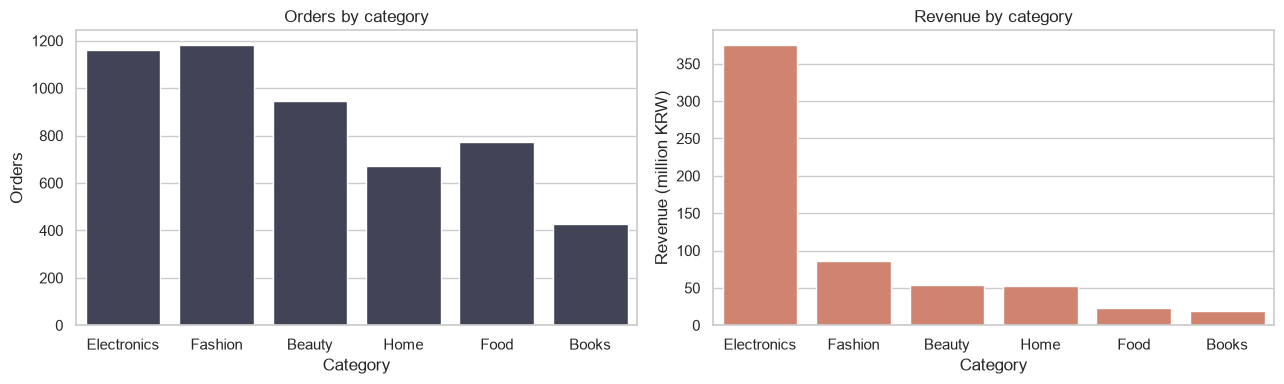

,orders,revenue,revenue_share_%
category,,,
Electronics,1161,"375,780,600.00",61.58
Fashion,1184,"85,978,700.00",14.09
Beauty,946,"53,361,200.00",8.75
Home,671,"52,374,300.00",8.58
Food,772,"23,171,500.00",3.80
Books,426,"19,522,600.00",3.20


In [24]:
# 차트 3: 막대그래프 - 카테고리별 주문 수와 매출
cat_stats = df.groupby("category").agg(orders=("order_id", "count"), revenue=("amount", "sum")).sort_values("revenue", ascending=False)  # 카테고리별 주문 수와 매출을 매출 큰 순으로 정리한다
cat_stats["revenue_share_%"] = cat_stats["revenue"] / cat_stats["revenue"].sum() * 100  # 전체 매출 중 비중(%)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))  # 좌우 2칸 그림판
sns.barplot(x=cat_stats.index, y=cat_stats["orders"], ax=axes[0], color="#3d405b")  # 왼쪽: 카테고리별 주문 수
axes[0].set_title("Orders by category")  # 왼쪽 제목
axes[0].set_xlabel("Category")  # 왼쪽 가로축 이름
axes[0].set_ylabel("Orders")  # 왼쪽 세로축 이름
sns.barplot(x=cat_stats.index, y=cat_stats["revenue"] / 1e6, ax=axes[1], color="#e07a5f")  # 오른쪽: 카테고리별 매출(백만 원)
axes[1].set_title("Revenue by category")  # 오른쪽 제목
axes[1].set_xlabel("Category")  # 오른쪽 가로축 이름
axes[1].set_ylabel("Revenue (million KRW)")  # 오른쪽 세로축 이름
plt.tight_layout()  # 칸 사이 여백을 자동으로 맞춘다
plt.show()  # 화면에 보여준다
cat_stats  # 정리한 표를 보여준다

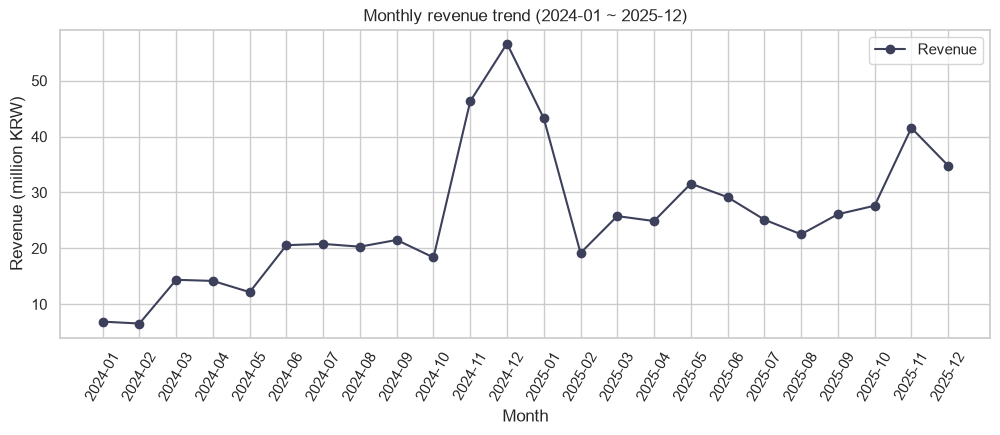

,revenue,orders
order_date,,
2024-12,"56,638,200.00",447
2024-11,"46,318,400.00",371
2025-01,"43,275,100.00",251
2025-11,"41,543,400.00",364


In [25]:
# 차트 6: 라인차트 - 월별 매출 추이
monthly = analyzer.monthly_sales("order_date", "amount")  # 월별 매출 합계
monthly_orders = df.groupby(df["order_date"].dt.to_period("M"))["order_id"].count()  # 월별 주문 수

fig, ax = plt.subplots(figsize=(12, 4))  # 그림판 한 칸
ax.plot(monthly.index.astype(str), monthly.to_numpy() / 1e6, marker="o", color="#3d405b", label="Revenue")  # 월별 매출(백만 원)을 점이 있는 선으로 그린다
ax.set_title("Monthly revenue trend (2024-01 ~ 2025-12)")  # 제목
ax.set_xlabel("Month")  # 가로축 이름
ax.set_ylabel("Revenue (million KRW)")  # 세로축 이름
ax.tick_params(axis="x", rotation=60)  # 월 이름이 겹치지 않게 기울인다
ax.legend()  # 범례를 표시한다
save(fig, "line_monthly.png")  # 이미지 파일로 저장한다
plt.show()  # 화면에 보여준다

pd.DataFrame({"revenue": monthly, "orders": monthly_orders}).sort_values("revenue", ascending=False).head(4)  # 매출이 큰 4개 달을 보여준다

### 해석
- 주문 수는 Fashion(1,184건)이 가장 많지만 매출은 Electronics가 전체의 61.6%로 가장 크다. Electronics 주문 1건 평균 금액은 323,670원으로 Food(30,015원)의 약 11배다.
- 월별 매출은 2024-12(5,664만 원), 2024-11(4,632만 원), 2025-01(4,328만 원), 2025-11(4,154만 원)이 가장 높다. 11~12월에 매년 매출이 뛴다.
- 연 매출은 2024년 2억 5,864만 원에서 2025년 3억 5,155만 원으로 약 36% 늘었다.
- 시사점: 연말(11~12월)에 맞춰 재고와 프로모션 예산을 미리 배치해야 한다.

## 7. RFM 기반 고객 세분화

| 지표 | 계산 | 좋은 방향 |
|---|---|---|
| Recency | 기준일(2025-12-31) - 마지막 구매일 (일) | 작을수록 좋다 |
| Frequency | 고유 주문 수 | 클수록 좋다 |
| Monetary | 총 구매 금액 (원본 `amount`) | 클수록 좋다 |

- 점수: 고객을 지표별로 줄 세운 뒤 5등분해서 1~5점을 준다(`pd.qcut`). 동점 때문에 구간이 깨지지 않게 먼저 `rank(method="first")`로 순위를 매긴다.
- Recency는 작을수록 좋으므로 부호를 바꿔 순위를 매긴다. 최근 구매자가 5점이다.

In [26]:
rfm = analyzer.calculate_rfm("customer_id", "order_date", "amount", order_col="order_id")  # 고객별 R, F, M 값과 점수를 계산한다
print("기준일:", df["order_date"].max().date())  # Recency 기준일 = 마지막 거래일
rfm.head()  # 앞 5명을 보여준다

기준일: 2025-12-31


,recency,frequency,monetary,r_score,f_score,m_score,rfm_total
customer_id,,,,,,,
C00001,124,5,"801,300.00",3,4,5,12
C00002,29,1,"20,000.00",4,1,1,6
C00003,59,1,"17,300.00",4,1,1,6
C00004,712,2,"101,300.00",1,2,2,5
C00005,170,5,"1,362,300.00",3,4,5,12


In [27]:
rfm[["recency", "frequency", "monetary"]].describe()  # R, F, M 값의 통계를 보여준다

,recency,frequency,monetary
count,"1,000.00","1,000.00","1,000.00"
mean,225.24,5.16,"610,188.90"
std,210.24,5.13,"1,105,890.80"
min,0.00,1.00,"6,800.00"
25%,34.00,2.00,"71,175.00"
50%,175.00,3.00,"198,250.00"
75%,380.25,7.00,"617,625.00"
max,730.00,28.00,"12,122,200.00"


### 세그먼트 규칙 (위에서부터 먼저 적용)

| 세그먼트 | 조건 | 의미 |
|---|---|---|
| VIP | R>=4, F>=4, M>=4 | 최근에, 자주, 많이 산다 |
| Loyal | R>=3, F>=3 | 꾸준히 산다 |
| New | R>=4, F<=2 | 최근에 처음 샀다 |
| At Risk | R<=2, F>=3 | 자주 샀지만 최근에 안 온다 |
| Churned | R<=2, F<=2 | 오래전에 조금 사고 떠났다 |
| Regular | 나머지 | 중간 고객 |

In [28]:
analyzer.segment_customers()  # 점수로 고객을 세그먼트로 나눈다
seg = analyzer.segment_summary()  # 세그먼트별 요약표를 만든다
seg  # 요약표를 보여준다

,customers,avg_recency,avg_frequency,avg_monetary,total_revenue,customer_share,revenue_share
segment,,,,,,,
VIP,218,32.24,12.50,"1,747,917.89","381,046,100.00",21.80,62.45
Loyal,213,144.44,5.51,"598,249.77","127,427,200.00",21.30,20.88
New,150,26.93,1.33,"93,446.67","14,017,000.00",15.00,2.30
Regular,19,185.32,1.95,"173,078.95","3,288,500.00",1.90,0.54
At Risk,169,390.36,3.98,"379,222.49","64,088,600.00",16.90,10.50
Churned,231,493.15,1.53,"87,971.86","20,321,500.00",23.10,3.33


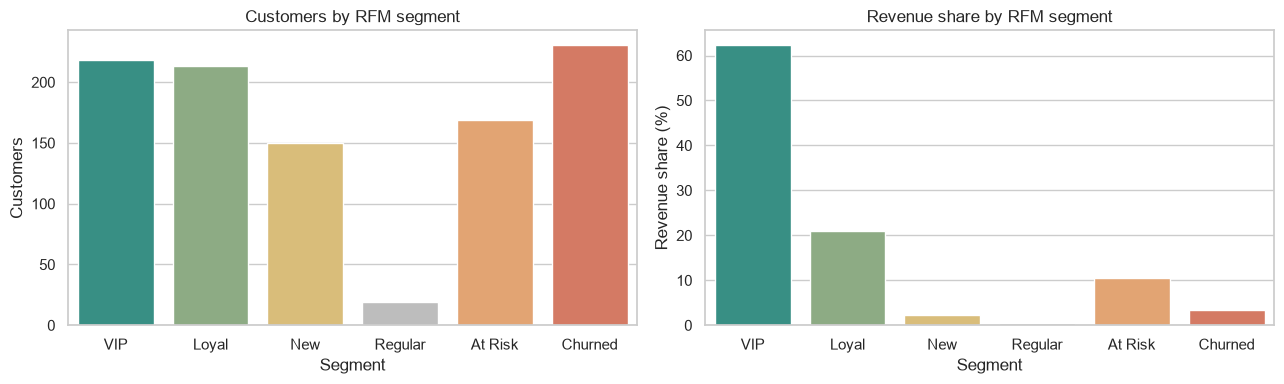

In [29]:
# 차트 3-2: 막대그래프 - 세그먼트별 고객 수와 매출 비중
fig, axes = plt.subplots(1, 2, figsize=(13, 4))  # 좌우 2칸 그림판
palette = dict(zip(SEGMENT_ORDER, ["#2a9d8f", "#8ab17d", "#e9c46a", "#bdbdbd", "#f4a261", "#e76f51"]))  # 세그먼트마다 정해 둔 색
sns.barplot(x=seg.index, y=seg["customers"], ax=axes[0], hue=seg.index, palette=palette, legend=False)  # 왼쪽: 세그먼트별 고객 수
axes[0].set_title("Customers by RFM segment")  # 왼쪽 제목
axes[0].set_xlabel("Segment")  # 왼쪽 가로축 이름
axes[0].set_ylabel("Customers")  # 왼쪽 세로축 이름
sns.barplot(x=seg.index, y=seg["revenue_share"], ax=axes[1], hue=seg.index, palette=palette, legend=False)  # 오른쪽: 세그먼트별 매출 비중
axes[1].set_title("Revenue share by RFM segment")  # 오른쪽 제목
axes[1].set_xlabel("Segment")  # 오른쪽 가로축 이름
axes[1].set_ylabel("Revenue share (%)")  # 오른쪽 세로축 이름
plt.tight_layout()  # 칸 사이 여백을 자동으로 맞춘다
save(fig, "bar_segment.png")  # 이미지 파일로 저장한다
plt.show()  # 화면에 보여준다

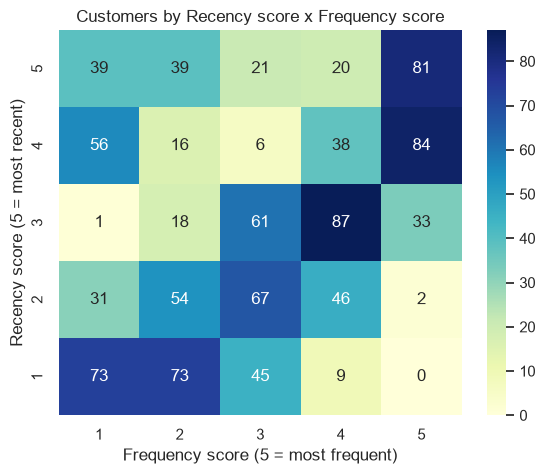

In [30]:
# 차트 4-2: 히트맵 - R 점수 x F 점수 고객 분포
grid = pd.crosstab(rfm["r_score"], rfm["f_score"]).sort_index(ascending=False)  # R 점수(행) x F 점수(열)별 고객 수를 센다. R 5점이 위로 오게 뒤집는다
fig, ax = plt.subplots(figsize=(6.5, 5))  # 그림판 한 칸
sns.heatmap(grid, annot=True, fmt="d", cmap="YlGnBu", ax=ax)  # 칸마다 고객 수를 적고 많을수록 진하게 칠한다
ax.set_title("Customers by Recency score x Frequency score")  # 제목
ax.set_xlabel("Frequency score (5 = most frequent)")  # 가로축 이름
ax.set_ylabel("Recency score (5 = most recent)")  # 세로축 이름
save(fig, "heatmap_rfm.png")  # 이미지 파일로 저장한다
plt.show()  # 화면에 보여준다

In [31]:
# 세그먼트별 선호 카테고리 (매출 기준)
seg_orders = df.merge(rfm[["segment"]], left_on="customer_id", right_index=True)  # 주문 표에 고객의 세그먼트를 붙인다
pd.crosstab(seg_orders["segment"], seg_orders["category"], values=seg_orders["amount"], aggfunc="sum", normalize="index").loc[SEGMENT_ORDER].mul(100).round(1)  # 세그먼트별로 카테고리 매출 비중(%)을 계산한다

category,Beauty,Books,Electronics,Fashion,Food,Home
segment,,,,,,
VIP,7.10,2.30,69.90,11.70,2.20,6.90
Loyal,8.70,5.20,55.30,17.40,4.10,9.20
New,18.90,3.10,27.70,21.50,11.20,17.50
Regular,9.10,1.00,61.80,18.70,6.00,3.40
At Risk,13.90,4.20,44.40,16.00,7.40,14.10
Churned,17.00,5.40,22.30,26.70,14.80,13.90


### 해석: 세그먼트별 특징

| 세그먼트 | 고객 수(비중) | 평균 Recency | 평균 주문 수 | 평균 구매액 | 매출 비중 | 특징 |
|---|---|---|---|---|---|---|
| VIP | 218명 (21.8%) | 32일 | 12.5회 | 1,747,918원 | 62.5% | 고객 5명 중 1명이 매출의 60% 이상. Electronics 비중이 가장 높다 |
| Loyal | 213명 (21.3%) | 144일 | 5.5회 | 598,250원 | 20.9% | 꾸준히 사지만 VIP보다 간격이 길다 |
| New | 150명 (15.0%) | 27일 | 1.3회 | 93,447원 | 2.3% | 최근 첫 구매. 두 번째 구매로 이어지는지가 관건 |
| Regular | 19명 (1.9%) | 185일 | 2.0회 | 173,079원 | 0.5% | 규칙 사이의 중간 고객 |
| At Risk | 169명 (16.9%) | 390일 | 4.0회 | 379,222원 | 10.5% | 예전엔 자주 샀지만 1년 넘게 안 왔다 |
| Churned | 231명 (23.1%) | 493일 | 1.5회 | 87,972원 | 3.3% | 가장 큰 그룹. 1~2번 사고 떠났다 |

- R-F 히트맵에서 R 4~5점, F 1점 칸에 95명이 있다. 최근에 왔지만 아직 한 번만 산 고객이다(New 후보).
- Frequency와 Monetary의 상관은 0.78로 높다. 자주 사는 고객이 돈도 많이 쓴다.
- 시사점: 매출은 VIP와 Loyal(전체 고객 43%)이 83%를 만든다. 이들의 이탈을 막는 것이 최우선이고, At Risk 169명은 복귀시키면 효과가 가장 큰 그룹이다.

## 8. 보너스: 코호트 분석 (재구매율)

- 코호트: 첫 구매 월이 같은 고객 묶음이다.
- 재구매율: 코호트 고객 중 N개월 뒤에도 구매한 고객 비율이다. 0개월 차는 항상 100%다.
- 개월 차이는 `연 x 12 + 월`을 빼서 반복문 없이 계산한다.

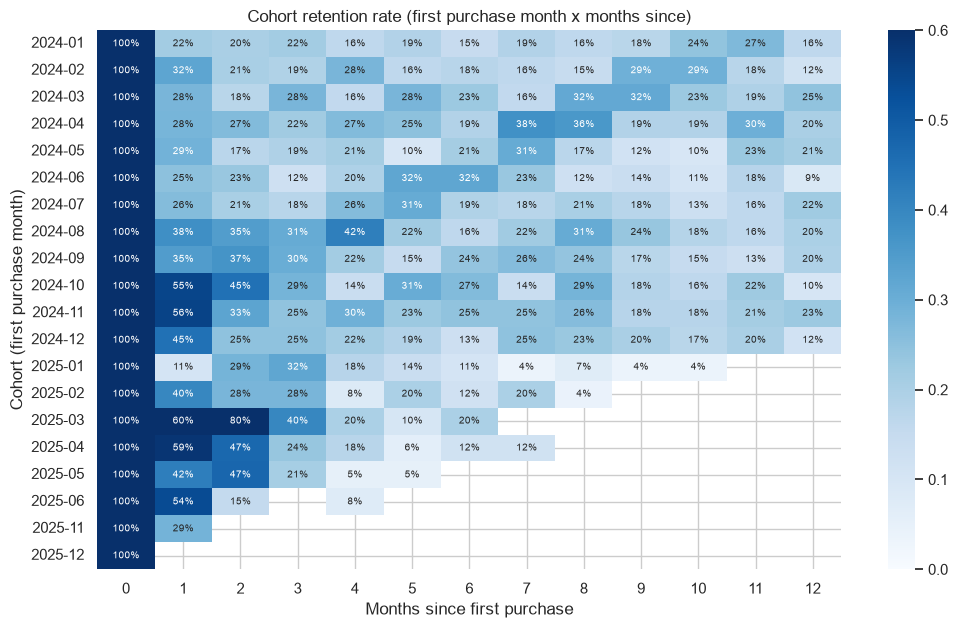

months_since_first_order
1   0.38
2   0.31
3   0.25
6   0.19
Name: avg_retention, dtype: float64

In [32]:
retention = analyzer.cohort_retention("customer_id", "order_date")  # 코호트별 재구매율 표를 만든다

# 차트 4-3: 히트맵 - 코호트 재구매율 (처음 12개월)
fig, ax = plt.subplots(figsize=(12, 7))  # 그림판 한 칸
sns.heatmap(retention.iloc[:, :13], annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=0.6, ax=ax, annot_kws={"size": 7})  # 처음 13개 열(0~12개월)을 퍼센트로 적고 진하기로 표현한다
ax.set_title("Cohort retention rate (first purchase month x months since)")  # 제목
ax.set_xlabel("Months since first purchase")  # 가로축 이름
ax.set_ylabel("Cohort (first purchase month)")  # 세로축 이름
save(fig, "heatmap_cohort.png")  # 이미지 파일로 저장한다
plt.show()  # 화면에 보여준다

retention[[1, 2, 3, 6]].mean().rename("avg_retention")  # 1, 2, 3, 6개월 뒤 평균 재구매율

### 해석
- 첫 구매 1개월 뒤 평균 재구매율은 38%, 3개월 뒤 25%, 6개월 뒤 19%다. 첫 3개월 안에 고객이 가장 많이 빠진다.
- 2024-10, 2024-11 코호트는 1개월 차 재구매율이 55~56%로 높다. 연말 성수기에 들어온 고객이 바로 다음 달에도 산다.
- 2025-07 ~ 2025-10에는 첫 구매 고객이 한 명도 없다(코호트 행이 비어 있다). 이 기간 신규 유입이 끊겼다는 뜻이므로 광고, 유입 채널 데이터로 원인을 확인해야 한다.
- 시사점: 첫 구매 후 30일 안에 두 번째 구매를 유도하는 장치(재구매 쿠폰, 리마인드 메시지)가 리텐션 곡선을 끌어올릴 수 있는 지점이다.

## 9. 보너스: Plotly 인터랙티브 차트

`Matplotlib` 그림은 이미지라서 점 하나하나의 값을 볼 수 없다. `Plotly`로 만든 차트는 마우스를 올리면 값이 보이고, 범례를 눌러 그룹을 켜고 끌 수 있다.

- 차트 7: 고객 한 명이 점 하나인 세그먼트 산점도. 올리면 고객 번호와 R, F, M 값이 보인다.
- 차트 8: 카테고리별 월별 매출 라인차트. 범례를 눌러 카테고리를 켜고 끌 수 있다.
- 두 차트는 `docs/interactive/`에 HTML로도 저장한다. 노트북 없이 브라우저에서 열 수 있다. (`plotly.js`를 CDN에서 불러오므로 인터넷이 필요하다)

In [33]:
import plotly.express as px  # 인터랙티브 차트 라이브러리 (보너스 3에서만 쓴다)

HTML_DIR = os.path.join(ROOT, "docs", "interactive")  # HTML 저장 폴더
os.makedirs(HTML_DIR, exist_ok=True)  # 폴더가 없으면 만든다


def save_html(fig, name):  # 차트를 HTML 파일로 저장하는 도우미 함수
    # 노트북 없이도 볼 수 있게 HTML 파일로 저장한다 (plotly.js는 CDN에서 불러온다)
    fig.write_html(os.path.join(HTML_DIR, name), include_plotlyjs="cdn")  # plotly.js는 인터넷에서 불러오게 해 파일을 가볍게 한다

In [34]:
# 차트 7: 인터랙티브 산점도 - 고객 세그먼트 (고객 1명 = 점 1개)
rfm_plot = rfm.reset_index()  # customer_id를 열로 꺼낸다
fig = px.scatter(  # 점 차트를 만든다
    rfm_plot,  # 그릴 데이터
    x="frequency",  # 가로축: 주문 횟수
    y="monetary",  # 세로축: 총 구매 금액
    color="segment",  # 세그먼트별로 색을 다르게 한다
    category_orders={"segment": SEGMENT_ORDER},  # 범례 순서를 고정한다
    hover_data=["customer_id", "recency", "r_score", "f_score", "m_score"],  # 올리면 보이는 값
    log_y=True,  # 금액 차이가 커서 세로축을 로그 눈금으로 본다
    title="Customer segments: frequency vs monetary (hover for details)",  # 차트 제목
    labels={"frequency": "Orders (frequency)", "monetary": "Total spend (KRW, log scale)"},  # 축 이름
)
fig.update_traces(marker=dict(size=7, opacity=0.7))  # 점 크기와 투명도
save_html(fig, "rfm_segments_scatter.html")  # HTML 파일로 저장한다
fig.show()  # 노트북에 보여준다

# 세그먼트별 주문 횟수와 구매 금액의 중앙값
rfm.groupby("segment")[["frequency", "monetary"]].median().loc[SEGMENT_ORDER]  # 세그먼트별 중앙값을 정해 둔 순서로 보여준다

,frequency,monetary
segment,,
VIP,11.00,"1,173,500.00"
Loyal,5.00,"321,800.00"
New,1.00,"53,700.00"
Regular,2.00,"78,200.00"
At Risk,4.00,"206,400.00"
Churned,2.00,"57,100.00"


In [35]:
# 차트 8: 인터랙티브 라인차트 - 카테고리별 월별 매출
monthly_cat = (  # 월 x 카테고리 매출표를 만든다
    df.assign(month=df["order_date"].dt.to_period("M").astype(str))  # 주문일을 "2025-01" 형태로 바꾼다
    .groupby(["month", "category"], as_index=False)["amount"].sum()  # 월 x 카테고리 매출 합계
)
monthly_cat["revenue_million"] = monthly_cat["amount"] / 1e6  # 백만 원 단위
fig = px.line(  # 선 차트를 만든다
    monthly_cat,  # 그릴 데이터
    x="month",  # 가로축: 월
    y="revenue_million",  # 세로축: 매출(백만 원)
    color="category",  # 카테고리마다 선 하나
    markers=True,  # 점도 같이 찍는다
    title="Monthly revenue by category (click legend to toggle)",  # 차트 제목
    labels={"month": "Month", "revenue_million": "Revenue (million KRW)"},  # 축 이름
)
fig.update_xaxes(tickangle=60)  # 월 이름이 겹치지 않게 기울인다
save_html(fig, "monthly_revenue_by_category.html")  # HTML 파일로 저장한다
fig.show()  # 노트북에 보여준다

# 11~12월 매출이 가장 큰 카테고리 확인용: 카테고리별 전체 매출 비중
(monthly_cat.groupby("category")["amount"].sum() / monthly_cat["amount"].sum()).sort_values(ascending=False).round(3)  # 카테고리별 전체 매출 비중을 큰 순으로 보여준다

category
Electronics   0.62
Fashion       0.14
Beauty        0.09
Home          0.09
Food          0.04
Books         0.03
Name: amount, dtype: float64

### 해석: 인터랙티브 차트
- 차트 7: `VIP`는 주문 횟수 중앙값 11회, 구매 금액 중앙값 약 117만 원으로 오른쪽 위에 모인다. `New`는 1회, 약 5만 원대로 왼쪽 아래에 있다.
- `At Risk`(4회, 약 21만 원)는 `Loyal`(5회, 약 32만 원)과 위치가 가깝다. 두 그룹은 얼마나 샀는지가 아니라 `Recency`(최근에 왔는지)로 갈린다. 점에 마우스를 올려 `recency` 값을 확인할 수 있다.
- 차트 8: 11~12월 매출의 66.5%가 `Electronics`다. 2024-12 `Electronics` 매출은 약 4,000만 원으로 같은 해 1~10월 월평균(약 833만 원)의 4.8배다. 연말 매출 급증은 전자기기가 이끈다.
- 범례를 눌러 `Electronics`를 끄면 나머지 카테고리의 월별 변화가 보인다. 정적 그래프에서는 `Electronics` 때문에 작은 카테고리의 움직임이 묻혔다.

## 10. 결론

| 번호 | 발견 | 근거 |
|---|---|---|
| 1 | VIP 21.8%가 매출 62.5%를 만든다 | 7장 세그먼트 표 |
| 2 | At Risk 169명은 1인당 379,222원을 썼지만 평균 390일째 구매가 없다 | 7장 세그먼트 표 |
| 3 | 첫 구매 후 3개월 안에 재구매율이 38%에서 25%로 떨어진다 | 8장 코호트 |
| 4 | 11~12월 매출이 다른 달보다 크게 높다 | 6장 라인차트 |

- 각 발견의 실행 방안과 검증 방법은 README.md의 "비즈니스 인사이트"에 정리했다.